# Differentiated Thyroid Cancer Recurrence 
This notebook:
1) Loads and audits the dataset
2) Performs reprocessing 
3) Produces plots

In [2]:
import os, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

## Load dataset

In [4]:
DATA_PATH = "./data/raw/1_differentiated_thyroid_cancer_recurrence.csv"

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Shape: (383, 17)


,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,F,No,No,No,Euthyroid,Single nodular goiter-left,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Indeterminate,No
1,34,F,No,Yes,No,Euthyroid,Multinodular goiter,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
2,30,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
3,62,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
4,62,F,No,No,No,Euthyroid,Multinodular goiter,No,Micropapillary,Multi-Focal,Low,T1a,N0,M0,I,Excellent,No


## Quick audit

In [5]:
print(df.info())

missing = df.isna().mean().sort_values(ascending=False)
print("\nTop missingness columns:")
print(missing.head(20))

print("\nNumber of duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Age                   383 non-null    int64 
 1   Gender                383 non-null    object
 2   Smoking               383 non-null    object
 3   Hx Smoking            383 non-null    object
 4   Hx Radiothreapy       383 non-null    object
 5   Thyroid Function      383 non-null    object
 6   Physical Examination  383 non-null    object
 7   Adenopathy            383 non-null    object
 8   Pathology             383 non-null    object
 9   Focality              383 non-null    object
 10  Risk                  383 non-null    object
 11  T                     383 non-null    object
 12  N                     383 non-null    object
 13  M                     383 non-null    object
 14  Stage                 383 non-null    object
 15  Response              383 non-null    ob

## Drop duplicate columns (No null)

In [7]:
df = df.drop_duplicates().reset_index(drop=True)
print("New shape after dropping duplicates:", df.shape)

New shape after dropping duplicates: (364, 17)


## Basic dataset summary

In [9]:
TARGET_COL = 'Recurred'

y_raw = df[TARGET_COL]
y_raw = y_raw.astype(str).str.strip().str.title()  # "No"/"Yes" standardized

X_raw = df.drop(columns=[TARGET_COL])

print("Target dtype:", y_raw.dtype)
print("Unique target values:", y_raw.unique())

print("\nFeature dtype counts:")
print(X_raw.dtypes.value_counts())

print("\nClass distribution:")
print(y_raw.value_counts(dropna=False))

Target dtype: object
Unique target values: ['No' 'Yes']

Feature dtype counts:
object    15
int64      1
Name: count, dtype: int64

Class distribution:
Recurred
No     256
Yes    108
Name: count, dtype: int64


## Target class distribution

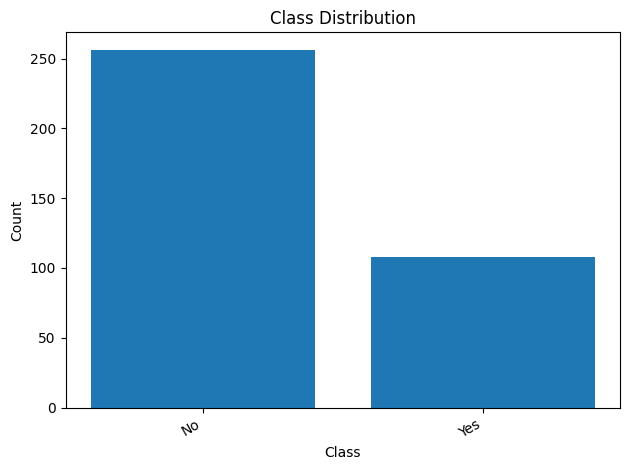

In [10]:
counts = y_raw.value_counts(dropna=False)

plt.figure()
plt.bar(counts.index.astype(str), counts.values)
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Age distribution by class

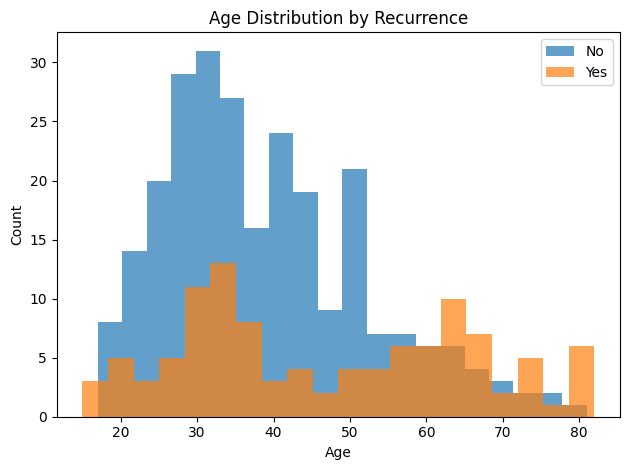

In [13]:
plt.figure()
ages_no = X_raw.loc[y_raw == "No", "Age"]
ages_yes = X_raw.loc[y_raw == "Yes", "Age"]
plt.hist(ages_no, bins=20, alpha=0.7, label="No")
plt.hist(ages_yes, bins=20, alpha=0.7, label="Yes")
plt.title("Age Distribution by Recurrence")
plt.xlabel("Age")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.show()

## Preprocessing and Encoding
Here we will:
1. Identify numerical and categorical columns.
2. Encode the target variable (`Recurred`) using Label Encoding.
3. Build a preprocessing pipeline to Scale numerical features and One-Hot Encode categorical features.

In [18]:
# 1. Identify feature types
numeric_features = X_raw.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_raw.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Found {len(numeric_features)} numerical features: {numeric_features}")
print(f"Found {len(categorical_features)} categorical features: {categorical_features}")

Found 1 numerical features: ['Age']
Found 15 categorical features: ['Gender', 'Smoking', 'Hx Smoking', 'Hx Radiothreapy', 'Thyroid Function', 'Physical Examination', 'Adenopathy', 'Pathology', 'Focality', 'Risk', 'T', 'N', 'M', 'Stage', 'Response']


In [19]:
# 2. Encode Target
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_processed = label_encoder.fit_transform(y_raw)

print("Target encoding mapping:")
for i, label in enumerate(label_encoder.classes_):
    print(f"  {label} -> {i}")

Target encoding mapping:
  No -> 0
  Yes -> 1


In [20]:
# 3. Preprocessing Pipeline for Features

# Numeric: Impute -> Scale
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical: Impute -> OneHot
# Note: sparse_output=False returns a dense array. (Use 'sparse=False' for older sklearn versions)
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)) 
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    verbose_feature_names_out=False  # Keeps original names where possible
)

# Apply transformations
X_processed = preprocessor.fit_transform(X_raw)

# Get feature names for the dataframe
try:
    feature_names = preprocessor.get_feature_names_out()
except AttributeError:
    # Component-wise fallback if get_feature_names_out isn't fully available
    ohe_feature_names = preprocessor.named_transformers_['cat']['encoder'].get_feature_names_out(categorical_features)
    feature_names = numeric_features + list(ohe_feature_names)

# Convert back to DataFrame for readability
X_processed_df = pd.DataFrame(X_processed, columns=feature_names)

print("Processed Feature Shape:", X_processed_df.shape)
display(X_processed_df.head())

Processed Feature Shape: (364, 55)


,Age,Gender_F,Gender_M,Smoking_No,Smoking_Yes,Hx Smoking_No,Hx Smoking_Yes,Hx Radiothreapy_No,Hx Radiothreapy_Yes,Thyroid Function_Clinical Hyperthyroidism,...,M_M1,Stage_I,Stage_II,Stage_III,Stage_IVA,Stage_IVB,Response_Biochemical Incomplete,Response_Excellent,Response_Indeterminate,Response_Structural Incomplete
0,-0.931780,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-0.474064,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-0.735616,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,1.356803,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1.356803,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
